<a href="https://colab.research.google.com/github/rosavnessa7/Colab_05/blob/main/Desafio2_Estatistica_Python_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###👣Passo 1 — Definir a pergunta de negócio e a coluna de análise


###Definir a pergunta de negócio e a coluna de análise

Pergunta 1: O tempo de espera dos pacientes está alto ?

Pergunta 2: O tempo de espera varia entre as classificações de risco?

Pergunta 3: O tempo entre os tpos de convencio é diferente?


---

###Colunas que auxiliam nas respostas

Pergunta 1: tempo_espera_min

Pergunta 2: tempo_espera_min vs nivel_triagem

Pergunta 3: tempo_espera_min vs tipo_convenio


---


###👣Passo 2 — Preparar o ambiente
### Célula 01 · Importações

O que esta célula faz: importa as bibliotecas que o notebook usa (arquivos, Google Colab, pandas e gráficos) e define configurações gerais, que valem para todos os gráficos. Não tem lacunas: copie e execute.

In [37]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

###👣Passo 3 — Obter os dados
### Carregar os arquivos CSV

Célula 02 · Carregar os arquivos CSV

In [38]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "pacientes"   # ex.: "livros"
NOME_TABELA_FATO = "atendimentos"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
pacientes -> 10500 linhas
atendimentos -> 42000 linhas


###Célula 03 · Conhecendo a tabela dimensão


O que esta célula faz: mostra quantas linhas e colunas tem a tabela dimensão e as 5 primeiras linhas. Olhe a chave primária e as colunas de cadastro. Não tem lacunas.

In [39]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10500 linhas e 6 colunas (variáveis)


,paciente_id,nome,data_nascimento,sexo,bairro,tipo_convenio
0,1,Juan Lopes,1983-12-08,M,Vila Madre Gertrudes 1ª Seção,SUS
1,2,Rafael Abreu,2017-06-21,outro,Vila Antena,SUS
2,3,Dra. Julia Montenegro,1989-01-28,M,São Francisco Das Chagas,SUS
3,4,Thiago Caldeira,1936-02-02,M,Santo Antônio,SUS
4,5,Letícia Porto,1994-08-19,F,Vila Tirol,SUS


###Célula 04 · Conhecendo a tabela fato
O que esta célula faz: o mesmo para a tabela fato. Olhe a chave estrangeira, as datas e as colunas numéricas. Não tem lacunas.

In [40]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 42000 linhas e 8 colunas (variáveis)


,atendimento_id,paciente_id,data_hora_chegada,sintoma_principal,nivel_triagem,tempo_espera_min,profissional_responsavel,desfecho
0,1,9633,2025-01-18 21:49:41,falta de ar,verde,37,Enfermeira 19,internado
1,2,2676,2025-04-27 08:55:07,falta de ar,amarelo,28,Enfermeiro 10,alta
2,3,4503,2026-07-08 06:54:14,vômito/náusea,amarelo,20,Enfermeiro 21,alta
3,4,7532,2026-05-04 12:21:15,tontura,verde,87,Tecnico Enfermagem 12,alta
4,5,2728,2025-07-12 08:48:22,dor de cabeça,verde,39,Tecnico Enfermagem 06,alta


###👣Passo 4 — Checar a base antes de calcular


###Célula 05 · Tipos das colunas


In [41]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   atendimento_id            42000 non-null  int64 
 1   paciente_id               42000 non-null  int64 
 2   data_hora_chegada         42000 non-null  object
 3   sintoma_principal         42000 non-null  object
 4   nivel_triagem             42000 non-null  object
 5   tempo_espera_min          42000 non-null  int64 
 6   profissional_responsavel  42000 non-null  object
 7   desfecho                  42000 non-null  object
dtypes: int64(3), object(5)
memory usage: 2.6+ MB


###Célula 06 · Valores ausentes
O que esta célula faz: conta os valores ausentes de cada coluna da tabela fato.



In [42]:
# 2) Valores ausentes por coluna (tabela fato).
print("\nValores ausentes por coluna:")
print(df_fato.isna().sum())


Valores ausentes por coluna:
atendimento_id              0
paciente_id                 0
data_hora_chegada           0
sintoma_principal           0
nivel_triagem               0
tempo_espera_min            0
profissional_responsavel    0
desfecho                    0
dtype: int64


Célula 07 · Linhas duplicadas

O que esta célula faz: conta os registros repetidos da tabela fato.




In [43]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


Célula 08 · Chave estrangeira

O que esta célula faz: confere se todo registro da fato aponta para um ID que existe na dimensão. Preencha com os nomes das colunas que você identificou na documentação do seu tema.



In [44]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "paciente_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "paciente_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


Warning

Se algum tipo estiver diferente do esquema (por exemplo, um número como object), se houver valor ausente em uma coluna que você vai usar ou se a chave estrangeira devolver False, investigue antes de seguir. O Python não avisa que a média ficou errada.

Leitura da conferência
Depois das quatro células, escreva em uma célula de texto o que a conferência mostrou. Use este modelo:

###**Leitura da conferência**

- (tamanho da tabela fato e se há linhas duplicadas)
- (se a chave estrangeira bate com a dimensão)
- (se a coluna de análise tem valores ausentes)
- (se há valores ausentes em outras colunas e por que estão vazios: erro ou não)




> A tabela fato tem 42000 linhas e 8 colunas (variáveis), onde não consta celulas vazias e duplicadas.ar blockquote


> As tabelas " fato" e "dimensão" possuem conpatibilidade na coluna Id_paciente







###👣Passo 5 — Medidas de tendência central e dispersão
Célula 09 · Checar a coluna numérica
O que esta célula faz: guarda a coluna numérica escolhida no Passo 1 como uma série (serie_numerica) e mostra quantos valores estão preenchidos e quantos estão ausentes.

In [45]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "tempo_espera_min"


# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 42000 | ausentes: 0


###Célula 10 · Medidas estatísticas
O que esta célula faz: calcula média, mediana, moda, desvio padrão, variância, mínimo, máximo e amplitude da coluna escolhida. O pandas ignora os valores ausentes no cálculo. Não tem lacunas.

In [46]:

# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))


,0
Média,63.40
Mediana,51.00
Moda,0.00
Desvio padrão,51.79
Variância,2681.74
Mínimo,0.00
Máximo,358.00
Amplitude,358.00


Média - mediana: 12.4



Tip

Olhe a média e a mediana lado a lado e o desvio padrão em relação à média. Se a média e a mediana forem muito diferentes, há algo puxando um dos lados. Você investiga isso no Passo 8.

###Passo 6 — Escrever as frases de insight
As frases de insight são escritas em uma célula de texto, logo abaixo das medidas. Escreva uma frase para a média, uma para a mediana e uma para o desvio padrão, mais uma decisão final. Use este modelo e substitua o que está entre parênteses:


 **A média de (coluna) é (valor)**. (O que a média significa para o seu tema.)
O tempo médio de espera é de 1h 06min, atendendo ao limite de 4 horas do Protocolo de Manchester, mas influenciado por casos extremos.

- **A mediana de (coluna) é (valor)**. (O que a mediana mostra e como ela se compara à média.)

- **O desvio padrão de (coluna) é (valor)**. (O que a variação mostra.)

- **Decisão final:** (escreva uma frase com a decisão que as três medidas apoiam.)


---



Metade dos pacientes espera até 51 minutos. Por ser menor que a média, indica que a maioria é atendida rapidamente, enquanto poucas esperas muito longas puxam a média para cima.

O valor de 51 minutos aponta alta variabilidade, mostrando falta de previsibilidade nos tempos de atendimento.

Embora a média geral e a mediana estejam abaixo do teto de 4 horas do Protocolo de Manchester, a alta dispersão (desvio padrão de 51 minutos) e a diferença em relação à média revelam gargalos operacionais pontuais que precisam de investigação para tornar o tempo de espera mais previsível e homogêneo para todos os pacientes.


###👣Passo 7 — Ampliar a análise: comparar grupos
Uma medida de toda a tabela esconde diferenças entre grupos. Compare a mesma coluna numérica entre categorias (tipo, local, faixa, status etc.), olhando média, mediana e desvio padrão juntos.

As categorias podem estar na tabela fato ou na tabela dimensão. Para usar uma coluna da dimensão, primeiro junte as duas tabelas pela chave estrangeira: cada registro da fato recebe as colunas do seu cadastro.

Célula 11 · Juntar a fato com a dimensão
O que esta célula faz: junta a tabela fato com a dimensão pela chave estrangeira (COLUNA_FK, da fato, com COLUNA_ID, da dimensão) e guarda o resultado em df_completo. As duas tabelas precisam ter o mesmo número de linhas depois da junção. Se aumentar, a junção duplicou registros. Não tem lacunas.

In [47]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais
df_completo.head()

Linhas da fato: 42000 | depois da junção: 42000


,atendimento_id,paciente_id,data_hora_chegada,sintoma_principal,nivel_triagem,tempo_espera_min,profissional_responsavel,desfecho,nome,data_nascimento,sexo,bairro,tipo_convenio
0,1,9633,2025-01-18 21:49:41,falta de ar,verde,37,Enfermeira 19,internado,José Nogueira,2012-07-31,F,Nova America,SUS
1,2,2676,2025-04-27 08:55:07,falta de ar,amarelo,28,Enfermeiro 10,alta,Alícia Araújo,2009-09-07,M,São Benedito,convenio
2,3,4503,2026-07-08 06:54:14,vômito/náusea,amarelo,20,Enfermeiro 21,alta,Stephany Silveira,1965-10-26,F,Vila Inestan,SUS
3,4,7532,2026-05-04 12:21:15,tontura,verde,87,Tecnico Enfermagem 12,alta,Ayla Oliveira,1993-01-31,M,Eymard,SUS
4,5,2728,2025-07-12 08:48:22,dor de cabeça,verde,39,Tecnico Enfermagem 06,alta,Heloisa Almeida,1940-11-13,F,Bairro Das Indústrias Ii,SUS


###Célula 12 · Comparar grupos por uma coluna da fato
O que esta célula faz: calcula quantidade, média, mediana e desvio padrão da coluna numérica em cada grupo de uma coluna categórica da fato, do maior para o menor valor médio.

In [48]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "nivel_triagem"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
nivel_triagem,,,,
azul,6349,149.47,150.0,57.38
verde,16934,69.62,69.0,29.34
amarelo,14631,34.64,34.0,16.78
laranja,3318,8.06,7.0,6.70
vermelho,768,1.73,0.0,2.66


Leitura da comparação

**Leitura por (coluna de grupo)**

- (grupo com a maior média e se a mediana confirma)
- (grupo com o maior desvio padrão: valores mais espalhados)
- (se os grupos têm médias parecidas, o que isso diz sobre a categoria)

Os resultados apontam que a triagem está funcionando corretamente, considerando o Protocolo Manchester, e isso explica por que o desvio padrão geral é tão alto (51 minutos).
Quando olhamos todos os dados misturados: o posto prioriza emergências (vermelho em ~1,7 min e laranja em ~8 min) e deixa casos sem gravidade (azul) aguardando ~2h30, mantendo todos os grupos dentro dos prazos clínicos seguros.








###Célula 13 · Comparar grupos por uma coluna da dimensão
O que esta célula faz: a mesma comparação, agora com uma coluna da dimensão, que só está disponível em df_completo por causa da junção da Célula 11. Escreva também a leitura, no mesmo modelo.

In [49]:
COLUNA_GRUPO = "tipo_convenio"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
tipo_convenio,,,,
convenio,8259,64.24,52.0,52.21
particular,4851,63.70,51.0,51.80
SUS,28890,63.11,51.0,51.66


Tip

Procure no resultado: qual grupo tem a maior média? A mediana confirma? Qual tem o maior desvio padrão (valores mais espalhados)? Um grupo com poucos registros (count baixo) merece cautela na conclusão. E se os grupos tiverem médias quase iguais, isso também é um resultado: a categoria não explica a diferença.


---
Existe equidade no tempo de espera: Diferente do agrupamento por nivel_triagem onde as cores mudavam drasticamente o tempo de espera, aqui as médias (~63 a 64 minutos), as medianas (51 a 52 minutos) e os desvios padrão (~52 minutos) são praticamente idênticos entre SUS, particular e convênio.  
E assim como todos os outros dados os desvios padrões mostram alta dispersão sendo um resultado que não vale a pena utilizar como parametro.


Conclusão: Isso comprova que a ordem e a agilidade do atendimento são definidas estritamente pela gravidade clínica (triagem), e não pela forma de pagamento ou tipo de convênio do paciente.

###👣Passo 8 — Tratar valores ausentes e outliers, e registrar a decisão
Um outlier é um valor fora do padrão. Ele pode ser um erro de dado (como 9999 minutos de espera) ou um caso real e raro. A pergunta é sempre a mesma: ele está distorcendo o resultado?

Célula 14 · Regra do IQR
O que esta célula faz: usa a regra do intervalo interquartil (IQR) para marcar valores muito distantes da faixa central e mostra os limites, a quantidade de candidatos a outlier e os valores extremos. Não tem lacunas.

In [50]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -59.00 a 173.00
Outliers: 2161 de 42000 valores
Maiores valores: [358, 346, 342, 341, 330]
Menores valores: [0, 0, 0, 0, 0]


Célula 15 · Medidas com e sem os candidatos a outlier
O que esta célula faz: compara média, mediana e desvio padrão com e sem os valores marcados na Célula 14. Não tem lacunas.

In [51]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,63.40,55.38
Mediana,51.00,48.00
Desvio padrão,51.79,39.09


Observe: a média muda muito e a mediana quase nada? Esse é o sinal clássico de outlier.


---


Warning

Não apague valor só porque ele é extremo. Quando muitos valores se repetem em um mesmo número (por exemplo, muitos zeros), a regra do IQR pode marcar como "outlier" valores que são casos reais. Decida e registre a decisão em uma célula de texto do notebook:

Decisão	Quando	O que registrar
Manter	O valor é plausível para o tema	Por que ele é um caso real
Tratar	Parece erro de preenchimento, mas dá para corrigir	Como foi corrigido
Excluir	É impossível para o tema (ex.: valor negativo de duração)	Quantos registros saíram e o motivo
Também registre o que fez com os valores ausentes (Célula 06): ignorados no cálculo, preenchidos ou removidos.


---



**Leitura e decisão registrada**

- (quantos valores a regra do IQR marcou, a partir de que valor, e como as medidas mudam sem eles)
- **Decisão:** (manter, tratar ou excluir) e o porquê
- **Valores ausentes:** (o que foi feito com eles e por quê)

A regra do IQR identificou 2.161 valores extremos, o que representa 5,15% do total de 42.000 registros. Esses casos correspondem a tempos de espera superiores a 2 horas e 53 minutos, chegando ao pico de 5 horas e 58 minutos, sem registros que fogem do normal na parte inferior da distribuição, já que o tempo mínimo é zero.

Quando esses extremos são desconsiderados, a média de 63,40 minutos e o desvio padrão de 51,79 minutos caem de forma expressiva, fazendo com que a média se aproxime da mediana de 51 minutos e reduzindo a forte assimetria à direita, contudo mantendo-se ainda a relação média acima da mediana e apontando uma diferença consideravel.

Decisão: **manter os outliers na base principal**. No contexto operacional de um posto de saúde, esperas de três a quase seis horas, de forma geral, não são erros de digitação, mas sim gargalos reais causados por superlotação ou falta de equipe.
 Excluir esses registros mascararia os piores cenários enfrentados pelos pacientes e comprometeria o diagnóstico para futuras mudanças no tempo de atendimento dos usuarios.




👣Passo 9 — Ler a distribuição dos valores
A distribuição mostra o formato de como os valores se espalham: concentrados no meio, inclinados para um lado ou espalhados. Três células descrevem esse formato antes de desenhar qualquer gráfico. Nenhuma tem lacunas.

Célula 16 · Assimetria (skew)
O que esta célula faz: calcula o quanto a distribuição se inclina para um dos lados.

In [52]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 1.42


Célula 17 · Percentis


In [57]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

0.10      9.0
0.25     28.0
0.50     51.0
0.75     86.0
0.90    133.0
Name: tempo_espera_min, dtype: float64


Célula 18 · Quantidade de valores por faixa
O que esta célula faz: divide os valores em 5 faixas de mesmo tamanho e conta quantos caem em cada uma.

In [54]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
tempo_espera_min,
"(-0.358, 71.6]",28024
"(71.6, 143.2]",10409
"(143.2, 214.8]",2775
"(214.8, 286.4]",741
"(286.4, 358.0]",51



Tip

Como ler
Assimetria positiva costuma vir com média maior que a mediana: poucos valores altos puxam a média.
Assimetria negativa costuma vir com média menor que a mediana.
Na dúvida, descreva em palavras: "a maioria dos valores fica entre X e Y, e poucos passam de Z".

---



Leitura da distribuição
Use este modelo na célula de texto:

**Leitura da distribuição**

- (valor da assimetria e o que ele indica sobre a cauda)
- (percentis: até que valor ficam 75% e 90% dos registros)
- (quantos registros estão na primeira faixa e quantos ficam nas faixas mais altas)
- Em palavras: (a maioria dos valores fica entre X e Y, e poucos passam de Z)


O valor de assimetria foi de 1,42, o que indica o formato e a inclinação da distribuição do tempo de atendimento em relação à triagem dos usuários. Esse resultado aponta uma forte assimetria à direita (ou positiva), mostrando que a grande maioria dos pacientes é atendida em tempos menores, mas a cauda da distribuição é puxada por um grupo menor de pacientes que enfrentou esperas longas e fora do normal.

Percentil: Embora a maioria dos usuarios tenham sido atendidos de forma mais ágil, com 50% abaixo de 51 minutos, conforme mediana, o intervalo entre os percentis 75 e 90, que varia de 86 a 133 minutos,mostrou que a parcela de usuários que enfrentou os maiores tempos de espera na unidade, sofrendo com os gargalos operacionais do tempo de atendimento.


---



👣Passo 10 — Redigir a recomendação de decisão
A recomendação é o centro do relatório. Ela precisa se apoiar em pelo menos duas medidas estatísticas (por exemplo, média e desvio padrão, ou mediana e a comparação entre grupos).

Em uma célula de texto do notebook, use este modelo:

## Recomendação

**Pergunta de negócio:** (a pergunta definida no Passo 1)

**Evidência 1:** (medida + valor + o que significa)
**Evidência 2:** (medida + valor + o que significa)

**Recomendação em uma frase:** (uma frase que alguém de fora da área entenderia)

**Limites da análise:** (os dados são fictícios; o que foi feito com outliers e ausentes, conforme o Passo 8)
Important

Cheque antes de seguir
Cada evidência cita a medida e o número.
A recomendação é uma decisão possível (o que fazer), não apenas uma descrição.
Tendência central e dispersão foram lidas juntas.
A base é fictícia: o texto não apresenta o resultado como fato real.

---

# Generated-by: AI (Gemini )
# AI-Generated-Date: 2026/11/17
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
Apoio sumarização dos dados e correção ortografica


Pergunta de negócio: O tempo de espera dos pacientes está alto, varia conforme a classificação de risco e muda de acordo com o tipo de convênio?

Evidência 1: O tempo de espera apresenta mediana de 51 minutos e média de 63,40 minutos (1h 06min), com assimetria de 1,42 (e percentis 75 e 90 entre 86 e 133 minutos), o que mostra que metade dos pacientes é atendida rapidamente, mas uma minoria enfrenta esperas muito longas que puxam a média para cima.

Evidência 2: O desvio padrão geral de 51,79 minutos aponta alta dispersão nos dados, explicada pela classificação de risco (onde emergências vermelhas esperam ~1,7 min e casos azuis sem gravidade aguardam ~2h30), enquanto entre os tipos de convênio (SUS, particular e convênio) as médias (63 a 64 min), medianas (51 a 52 min) e desvios padrão (52 min) permanecem praticamente idênticos.

Recomendação em uma frase: Manter os critérios atuais de priorização clínica — pois o atendimento respeita a gravidade e não discrimina por convênio — e direcionar esforços operacionais apenas para reduzir os gargalos e melhorar o fluxo dos casos não urgentes (classificação azul) nos horários de pico.

Limites da análise: Esta avaliação baseia-se em uma base de dados fictícia de 42.000 registros (sem valores ausentes), na qual optou-se por manter os 2.161 outliers (5,15% dos casos, com esperas de 2h 53min a 5h 58min) por representarem cenários plausíveis de superlotação que não devem ser ocultados na simulação.




👣Passo 11 — Gráficos simples e legíveis (diferencial)
Só faça este passo depois de ter os Passos 7 a 10 completos. Um gráfico simples e legível vale mais que um gráfico bonito e confuso. São dois gráficos, cada um em uma célula, com título e eixos identificados. Substitua os textos dos eixos pelos do seu tema.

Célula 19 · Histograma
O que esta célula faz: desenha o histograma da coluna analisada, com a curva da distribuição (kde=True) e as linhas da média (vermelha) e da mediana (verde tracejada).


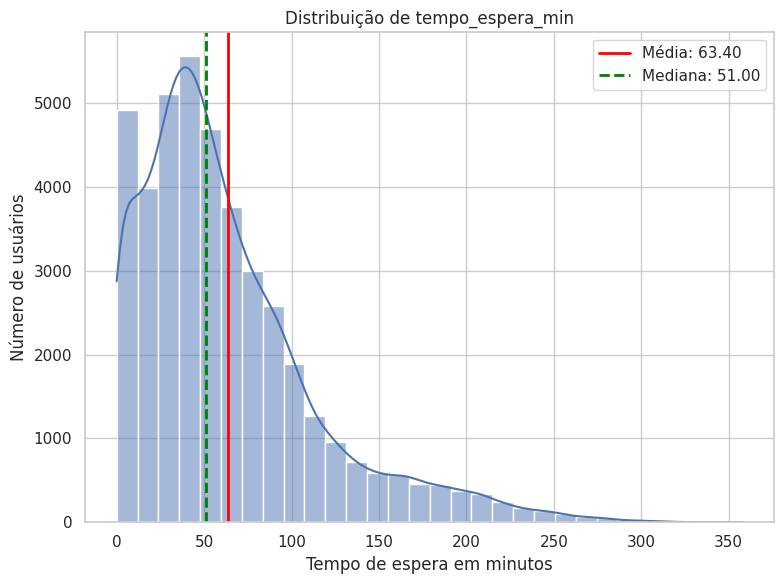

In [62]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("Tempo de espera em minutos")        # lacuna: nome do eixo x, em linguagem simples
plt.ylabel("Número de usuários")            # lacuna: nome do eixo y, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()


As barras do gráfico e a curva mostram que a maior concentração de pacientes se encontra nos menores tempos de espera, com o pico mais alto logo no início.
A linha vertical tracejada verde marca a mediana de 51,00 minutos, enquanto a linha vermelha contínua aponta a média de 63,40 minutos.
O fato de a linha vermelha estar posicionada à direita da verde evidencia visualmente como a média é puxada para cima por causa da cauda longa à direita.   

Célula 20 · Boxplot
O que esta célula faz: desenha o boxplot: a caixa é a faixa central (25% a 75%) e os pontos fora são candidatos a outlier. A linha vermelha marca a média.

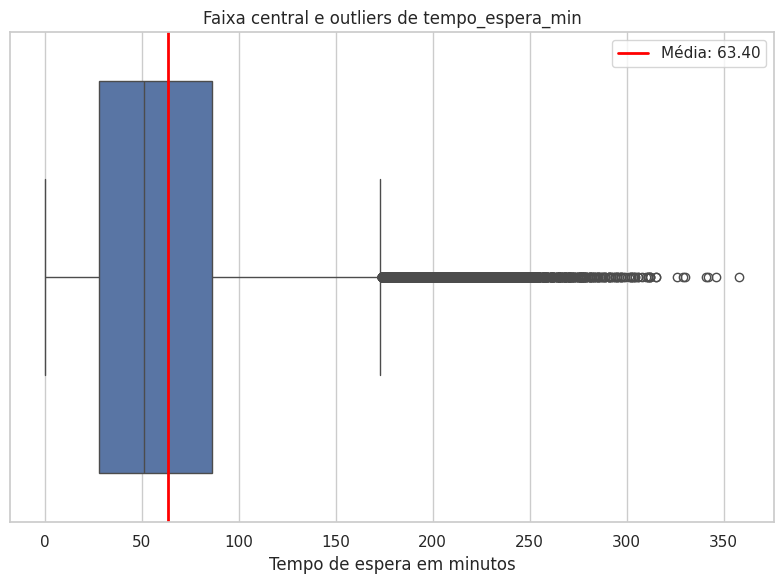

In [61]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("Tempo de espera em minutos")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

O gráfico mostra a distribuição do tempo de espera dos usuários no posto de saúde e comprova o comportamento assimétrico do atendimento.  

A caixa azul concentra a faixa central onde está a maior parte dos atendimentos.

A linha preta na vertical interna a caixa marcando a mediana de 51 minutos.

Logo à direita dela, a linha vermelha representa a média de 1hora e 6 minutos evidenciando como o valor médio é puxado para cima em relação ao tempo normal de espera.   

Além do limite superior da haste, depois de 170 min, a longa sequência de pontos à direita ilustra os outliers — casos de pacientes que enfrentaram esperas extremas, chegando a quase 6 horas.

O gráfico deixa claro que, embora o fluxo central do posto funcione dentro de um tempo razoável, existem gargalos pontuais severos que distorcem a média e geram dispersão no atendimento.

Note

Escreva, abaixo dos gráficos, uma frase dizendo o que eles mostram e qual insight eles ilustram. Gráfico sem frase de leitura não conta como análise.